# Ajuste Fino do YOLO

No material anterior, montamos e treinamos do zero um detector no estilo do YOLO. Na prática, ninguém treina um detector do zero: parte-se de um modelo pré-treinado em um dataset grande e faz-se o **ajuste fino** (*fine-tuning*) para as classes do problema, como fizemos com classificadores na transferência de aprendizado.

Vamos usar a biblioteca **Ultralytics** (`pip install -U ultralytics`), que implementa as versões recentes do YOLO. O YOLO26, a versão que usamos aqui, precisa da Ultralytics 8.4 ou mais nova. O caminho é:

1. fazer inferência com um modelo pré-treinado;
2. entender o formato de dataset que o YOLO espera e ajustar o modelo em um dataset pronto;
3. reunir as imagens e rotular o **seu próprio dataset** de detecção e ajustar o YOLO para ele.

In [1]:
import os
import random
import shutil
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageOps
from ultralytics import YOLO
from ultralytics.utils import ASSETS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


## Inferência

A Ultralytics distribui o **YOLO26**, a versão mais recente do YOLO, em cinco tamanhos: `n` (*nano*), `s`, `m`, `l` e `x`. Quanto maior, mais preciso e mais lento. Todos foram treinados no **COCO**, um dataset com 80 classes de objetos do dia a dia: pessoas, carros, animais, móveis, comida. Os pesos são baixados na primeira vez que o modelo é carregado.

In [2]:
model = YOLO("yolo26n.pt")

print(f"{len(model.names)} classes")
print(list(model.names.values())[:20])

80 classes
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow']


O método `predict` recebe um caminho, uma URL, uma imagem PIL ou uma lista deles, e devolve uma lista de resultados, um por imagem. Vamos usar uma foto de exemplo que vem com a biblioteca. O `conf` é o limiar de confiança. O YOLO26 dispensa a supressão de não máximos do material anterior: ele é treinado para prever uma única caixa por objeto, então a saída da rede já é a lista final de detecções. Nas versões anteriores, como o YOLO11, a supressão vem embutida no `predict`, com o limiar de IoU no argumento `iou`.

O `plot` de um resultado devolve a imagem com as caixas desenhadas, com os canais na ordem BGR, então invertemos a ordem para o matplotlib.

image 1/1 /home/alomyr/Projetos/UFRN-06/APRENDIZADO-PROFUNDO/.venv/lib/python3.14/site-packages/ultralytics/assets/bus.jpg: 640x480 4 persons, 1 bus, 3.8ms


Speed: 27.7ms preprocess, 3.8ms inference, 15.7ms postprocess per image at shape (1, 3, 640, 480)


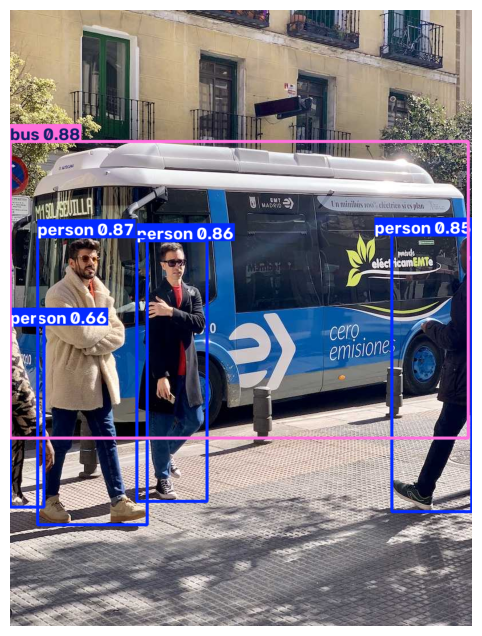

In [3]:
results = model.predict(ASSETS / "bus.jpg", conf=0.25)
result = results[0]

plt.figure(figsize=(6, 8))
plt.imshow(result.plot()[:, :, ::-1])   # BGR -> RGB
plt.axis("off")
plt.show()

As caixas ficam em `result.boxes`. Cada uma tem a classe (`cls`), a confiança (`conf`) e as coordenadas em vários formatos: `xyxy` são os cantos em pixels e `xywhn` é o formato do material anterior, com centro e tamanho divididos pelo tamanho da imagem.

In [4]:
for box in result.boxes:
    label = model.names[int(box.cls)]
    x0, y0, x1, y1 = box.xyxy[0].tolist()
    print(f"{label:10s} confiança {box.conf.item():.2f}, cantos ({x0:.0f}, {y0:.0f}) e ({x1:.0f}, {y1:.0f})")

bus        confiança 0.88, cantos (0, 230) e (803, 751)
person     confiança 0.87, cantos (49, 398) e (240, 902)
person     confiança 0.86, cantos (223, 405) e (345, 861)
person     confiança 0.85, cantos (670, 394) e (810, 879)
person     confiança 0.66, cantos (0, 553) e (60, 871)


## Ajuste fino

O modelo pré-treinado só conhece as 80 classes do COCO. Para detectar outras coisas, fazemos o ajuste fino: a rede mantém as camadas que extraem características, que servem para qualquer imagem, e a camada final é trocada por uma com o número de classes do novo problema. A Ultralytics faz essa troca sozinha, a partir da lista de classes do dataset. Só precisamos entregar os dados no formato certo.

### O formato do dataset

O YOLO espera as imagens e as anotações em pastas separadas, com uma subpasta para cada conjunto:

```
dataset/
    data.yaml
    images/train/  images/val/
    labels/train/  labels/val/
```

Cada imagem `images/train/foto.jpg` tem um arquivo de anotação `labels/train/foto.txt`, com uma linha por objeto:

```
classe x y w h
```

no mesmo formato do material anterior: o índice da classe, o centro e o tamanho da caixa, divididos pelo tamanho da imagem. Uma imagem sem objetos pode ficar sem arquivo de anotação; ela serve de exemplo de fundo.

Pode haver também uma pasta `test`, com imagens que só são usadas no fim, para a avaliação final.

O `data.yaml` diz onde estão as pastas e o nome de cada classe, na ordem dos índices.

In [5]:
def write_data_yaml(dataset_dir, classes):
    path = os.path.join(dataset_dir, "data.yaml")
    with open(path, "w") as f:
        f.write(f"path: {os.path.abspath(dataset_dir)}\n")
        f.write("train: images/train\n")
        f.write("val: images/val\n")
        if os.path.exists(os.path.join(dataset_dir, "images", "test")):
            f.write("test: images/test\n")
        f.write("names:\n")
        for index, name in enumerate(classes):
            f.write(f"  {index}: {name}\n")
    return path

### Exemplo: equipamentos de proteção individual

Um dos usos mais comuns de detecção na indústria é a segurança do trabalho: câmeras em obras e fábricas verificam se cada pessoa está usando os **equipamentos de proteção individual** (EPIs) exigidos, como capacete, colete, luvas, botas e óculos. Vamos usar o **construction-ppe**, um dataset de fotos de obras publicado pela Ultralytics no GitHub, com 1132 imagens de treino, 143 de validação e 141 de teste.

São 11 classes. Além de pessoas (`Person`) e de cada equipamento (`helmet`, `vest`, `gloves`, `boots`, `goggles`), há classes para a **ausência** de cada um: `no_helmet` marca uma cabeça sem capacete, `no_gloves` uma mão sem luva, e assim por diante. Na prática, o que interessa é justamente detectar quem está sem o equipamento.

O dataset tem os problemas típicos de dados reais, e vale olhar para eles antes de treinar:

- **nomes inconsistentes**: a classe 5 se chama `none`, mas, olhando as caixas, ela marca torsos sem colete. Na nossa lista de classes ela vira `no_vest`. Os índices dos arquivos de anotação continuam os mesmos; só o nome muda;
- **classes desbalanceadas**: há quase 1800 pessoas no treino, mas menos de 100 caixas de `no_boots`;
- **objetos pequenos**: luvas e óculos ocupam menos de 1% da área da imagem;
- **arquivos sobrando**: algumas anotações do treino não têm imagem correspondente. A Ultralytics as ignora.

In [6]:
ppe_dir = "data/construction-ppe"
url = "https://github.com/ultralytics/assets/releases/download/v0.0.0/construction-ppe.zip"
ppe_classes = ["helmet", "gloves", "vest", "boots", "goggles", "Person",
               "no_helmet", "no_goggle", "no_gloves", "no_boots", "forklift", "no_vest"]

if not os.path.exists(os.path.join(ppe_dir, "labels", "train")):
    if not os.path.exists("data/construction-ppe.zip"):
        urllib.request.urlretrieve(url, "data/construction-ppe.zip")
    with zipfile.ZipFile("data/construction-ppe.zip") as z:
        z.extractall("data")

ppe_yaml = write_data_yaml(ppe_dir, ppe_classes)
print(open(ppe_yaml).read())

train_labels_dir = os.path.join(ppe_dir, "labels", "train")
n_boxes = [0] * len(ppe_classes)
for label_name in os.listdir(train_labels_dir):
    for line in open(os.path.join(train_labels_dir, label_name)).read().splitlines():
        if line.strip():
            n_boxes[int(line.split()[0])] += 1

for name, count in zip(ppe_classes, n_boxes):
    print(f"{name:10s} {count:5d} caixas no treino")

path: /home/alomyr/Projetos/UFRN-06/APRENDIZADO-PROFUNDO/tarefa2° /data/construction-ppe
train: images/train
val: images/val
names:
  0: helmet
  1: gloves
  2: vest
  3: boots
  4: goggles
  5: Person
  6: no_helmet
  7: no_goggle
  8: no_gloves
  9: no_boots
  10: forklift
  11: no_vest

helmet      1282 caixas no treino
gloves      1548 caixas no treino
vest        1476 caixas no treino
boots       2003 caixas no treino
goggles      612 caixas no treino
Person      1962 caixas no treino
no_helmet    634 caixas no treino
no_goggle    265 caixas no treino
no_gloves    839 caixas no treino
no_boots     569 caixas no treino
forklift     275 caixas no treino
no_vest      437 caixas no treino


A função `show_labels` lê um arquivo de anotação e desenha as caixas sobre a imagem, com uma cor para cada classe. Ela serve para conferir se as anotações estão certas antes de treinar, e vamos usá-la de novo no seu dataset.

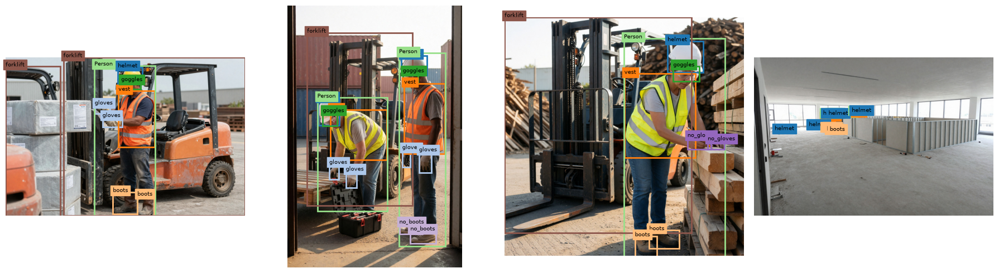

In [7]:
colors = [plt.cm.tab20(index) for index in range(20)]


def show_labels(ax, image_path, label_path, classes):
    image = Image.open(image_path).convert("RGB")
    W, H = image.size
    ax.imshow(image)
    ax.axis("off")

    if not os.path.exists(label_path):
        return   # imagem de fundo, sem objetos
    for line in open(label_path).read().splitlines():
        label, x, y, w, h = line.split()
        color = colors[int(label) % len(colors)]
        x, y, w, h = float(x) * W, float(y) * H, float(w) * W, float(h) * H
        ax.add_patch(plt.Rectangle((x - w / 2, y - h / 2), w, h, linewidth=2, edgecolor=color, facecolor="none"))
        ax.text(x - w / 2, y - h / 2, classes[int(label)], color="black", backgroundcolor=color, fontsize=7)


train_images_dir = os.path.join(ppe_dir, "images", "train")
names = random.Random(0).sample(sorted(os.listdir(train_images_dir)), 4)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, name in zip(axes, names):
    label_name = os.path.splitext(name)[0] + ".txt"
    show_labels(ax, os.path.join(train_images_dir, name), os.path.join(train_labels_dir, label_name), ppe_classes)
plt.tight_layout()
plt.show()

### Treinando

O `train` recebe o `data.yaml` e os hiperparâmetros principais:

- `epochs`: o número de épocas;
- `imgsz`: o tamanho para o qual as imagens são redimensionadas, múltiplo de 32. O padrão é 640;
- `batch`: o tamanho do lote;
- `project` e `name`: a pasta onde ficam os resultados, aqui `runs/ppe`.

O `project` vai com o caminho absoluto: as versões recentes da Ultralytics colocam um caminho relativo dentro de outra pasta, `runs/detect/`, e os pesos acabariam em `runs/detect/runs/ppe`. Com o caminho absoluto, eles ficam onde pedimos.

O otimizador, a taxa de aprendizado e o aumento de dados vêm configurados. Ao fim de cada época, o modelo é avaliado no conjunto de validação, e os pesos da melhor época ficam em `runs/ppe/weights/best.pt`.

In [8]:
runs_dir = os.path.abspath("runs")

model = YOLO("yolo26n.pt")
model.train(data=ppe_yaml, epochs=30, imgsz=640, batch=16, project=runs_dir, name="ppe", exist_ok=True)

New https://pypi.org/project/ultralytics/8.4.217 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.216 🚀 Python-3.14.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3070, 7839MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/construction-ppe/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ppe, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0, pr

Overriding model.yaml nc=80 with nc=12



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (1,037 outputs left out)

               no_vest         84        130      0.883      0.615      0.693      0.478


Speed: 0.2ms preprocess, 1.5ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /home/alomyr/Projetos/UFRN-06/APRENDIZADO-PROFUNDO/tarefa2° /runs/ppe


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7afeb01b7540>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,  

No início do registro do treino, duas linhas mostram o ajuste fino acontecendo: `Overriding model.yaml nc=80 with nc=11` troca as 80 classes do COCO pelas 11 classes do dataset, e `Transferred ... items from pretrained weights` diz quantos tensores de pesos vieram do modelo pré-treinado. A classe `Person` também existe no COCO, como `person`, e a linha `Remapped 1/11 cls head rows` mostra que a Ultralytics reaproveitou os pesos dela na nova cabeça; as outras 10 classes começam do zero. Os que ficam de fora são os da parte da cabeça que prevê as classes, cujo formato depende do número de classes; esses começam do zero.

### Avaliação

A métrica padrão de detecção é o **mAP** (*mean average precision*). Para cada classe, as detecções são ordenadas pela confiança e, conforme o limiar de confiança desce, a precisão e a revocação vão mudando; a **AP** é a área sob essa curva de precisão por revocação. O mAP é a média da AP sobre as classes:

$$
\text{mAP} = \frac{1}{C} \sum_{c=1}^{C} \text{AP}_c
$$

em que $C$ é o número de classes. Uma detecção só conta como acerto se tiver IoU acima de um limiar com uma caixa verdadeira. O **mAP50** usa o limiar 0,5. O **mAP50-95** é a média para os limiares de 0,5 a 0,95, e cobra caixas mais justas.

Com várias classes, vale olhar também a AP de cada uma: um mAP razoável pode esconder uma classe que o modelo quase nunca acerta. E num sistema de segurança, a classe que importa é a de quem está sem o equipamento, como `no_helmet`, não a média.

Avaliamos no conjunto de validação, que foi usado durante o treino para escolher a melhor época, e no de teste, que o modelo nunca viu. O número a reportar é o do teste.

In [9]:
ppe_model = YOLO(os.path.join(runs_dir, "ppe", "weights", "best.pt"))
val_metrics = ppe_model.val(data=ppe_yaml, split="val", verbose=False)
has_test = os.path.exists(os.path.join(ppe_dir, "images", "test"))
eval_metrics = ppe_model.val(data=ppe_yaml, split="test", verbose=False) if has_test else val_metrics

print(f"validação: mAP50 {val_metrics.box.map50:.3f}, mAP50-95 {val_metrics.box.map:.3f}")
if has_test:
    print(f"teste:     mAP50 {eval_metrics.box.map50:.3f}, mAP50-95 {eval_metrics.box.map:.3f}")

split_label = "teste" if has_test else "validação"
print(f"\nAP50 na {split_label}, da melhor para a pior classe:")
eval_ap50 = sorted(zip(eval_metrics.box.ap50, eval_metrics.box.ap_class_index), reverse=True)
for ap50, index in eval_ap50:
    print(f"{ppe_classes[index]:10s} {ap50:.3f}")

Ultralytics 8.4.216 🚀 Python-3.14.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3070, 7839MiB)


YOLO26n summary (fused): 121 layers, 2,392,408 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 8916.4±553.8 MB/s, size: 852.4 KB)


val: Scanning /home/alomyr/Projetos/UFRN-06/APRENDIZADO-PROFUNDO/tarefa2° /data/construction-ppe/labels/val.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 119.8Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 7% ╸─────────── 1/13 4.7s/it 1.4s<55.9s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 15% ━╸────────── 2/13 2.0it/s 1.6s<5.5s

... (6 outputs left out)

                   all        200       2961      0.819      0.677      0.732      0.526


Speed: 0.5ms preprocess, 1.8ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to /home/alomyr/Projetos/UFRN-06/APRENDIZADO-PROFUNDO/runs/detect/val


validação: mAP50 0.732, mAP50-95 0.526

AP50 na validação, da melhor para a pior classe:
Person     0.947
goggles    0.942
vest       0.889
helmet     0.833
forklift   0.804
gloves     0.795
boots      0.760
no_boots   0.724
no_vest    0.697
no_helmet  0.635
no_gloves  0.632
no_goggle  0.131


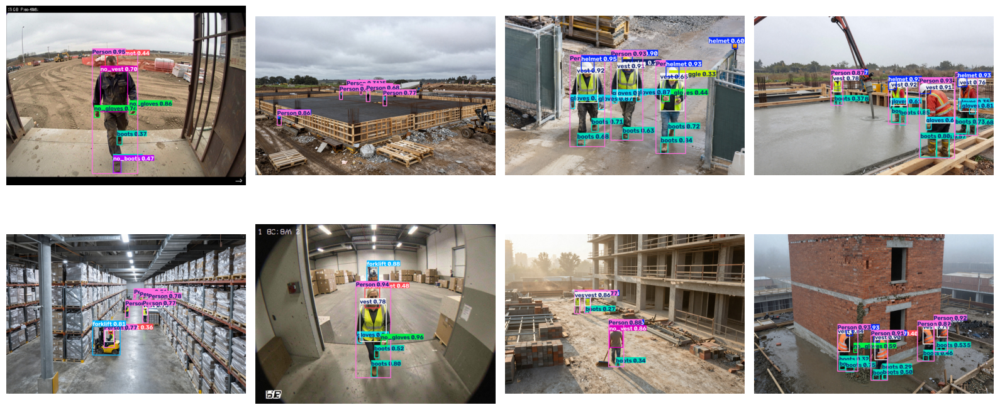

In [10]:
eval_split = "test" if os.path.exists(os.path.join(ppe_dir, "images", "test")) else "val"
test_dir = os.path.join(ppe_dir, "images", eval_split)
paths = [os.path.join(test_dir, name) for name in sorted(os.listdir(test_dir))[:8]]
results = ppe_model.predict(paths, verbose=False)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, result in zip(axes.flat, results):
    ax.imshow(result.plot()[:, :, ::-1])
    ax.axis("off")
plt.tight_layout()
plt.show()

Compare a AP de cada classe com o que vimos nos dados. Os equipamentos, mesmo os pequenos como luvas e óculos, costumam ser bem detectados. As classes de **ausência** ficam bem atrás, e `no_boots`, a mais rara, quase nunca é encontrada. Detectar a falta de algo é mais difícil: uma cabeça sem capacete se parece com qualquer cabeça, e o modelo precisa aprender que a diferença está no que não aparece. Além disso, essas classes têm bem menos exemplos.

O problema é que, num sistema de segurança, as classes de ausência são exatamente as que importam: um alarme de `no_helmet` que quase nunca dispara não serve para nada, por melhor que seja o mAP médio. Num projeto real, os próximos passos seriam atacar essas classes: juntar e rotular mais imagens de pessoas sem equipamento, usar um modelo maior e um `imgsz` maior, ou mudar a formulação do problema, por exemplo detectando só pessoas e cabeças e classificando depois se cada uma está com o equipamento.

## O seu detector

Agora cada um monta o seu dataset de detecção, do começo ao fim: reunir as imagens, rotular os objetos, organizar os arquivos no formato do YOLO e fazer o ajuste fino. O código é por sua conta; as funções `write_data_yaml` e `show_labels` e as células do exemplo acima podem ser reaproveitadas.

### Exercício: as fotos

Escolha de 1 a 3 classes de objetos e reúna as imagens. Elas podem vir de onde for mais prático:

- **fotos suas**, tiradas com o celular;
- **imagens da internet**, baixadas à mão ou por *scraping*. A biblioteca `icrawler` (`pip install icrawler`) baixa os resultados de uma busca de imagens: `BingImageCrawler(storage={"root_dir": "data/meu_detector/fotos/caneca"}).crawl(keyword="caneca", max_num=100)`. Ela numera os arquivos a partir de `000001` em cada pasta, então use uma pasta por busca;
- **quadros de um vídeo**, extraídos com o `cv2.VideoCapture`, pegando um quadro a cada um ou dois segundos;
- uma mistura dessas fontes, que costuma dar a maior variedade.

Algumas dicas:

- objetos com contorno bem definido são mais fáceis de rotular e de detectar: canecas, canetas, chaves, frutas, tênis, controles remotos;
- varie o fundo, a iluminação, a distância e o ângulo, e tenha imagens com vários objetos, inclusive de classes diferentes. Um modelo treinado só com fotos na mesma mesa aprende a mesa; um treinado só com fotos de catálogo, com o objeto centralizado em fundo branco, não reconhece o objeto em uma cena real;
- algumas imagens sem nenhum dos objetos ajudam o modelo a não detectar coisas no fundo;
- comece com cerca de 50 a 100 imagens: cada uma vai ser rotulada à mão.

Imagens da internet e de vídeo têm cuidados próprios. A busca devolve resultados errados, ilustrações e imagens repetidas; olhe todas e descarte o que não serve. Imagens repetidas ou quadros quase iguais de um vídeo que caiam uma no treino e outra na validação deixam a validação otimista demais. E imagens da internet têm direitos autorais: para um trabalho de aula, tudo bem, mas não publique o dataset.

Coloque as imagens em uma pasta, por exemplo `data/meu_detector/fotos`, e prepare-as para a rotulação, salvando o resultado em outra pasta, como `data/meu_detector/images`:

- fotos de celular às vezes vêm "deitadas", com a rotação guardada só nos metadados (EXIF). O `ImageOps.exif_transpose` do PIL aplica essa rotação à imagem;
- imagens grandes deixam a rotulação e o treino lentos. Reduza o maior lado para cerca de 1024 pixels, mantendo a proporção (`Image.thumbnail`);
- salve tudo em JPEG, convertendo para RGB (`image.convert("RGB")`), já que imagens da internet podem vir em PNG com transparência, WebP ou GIF. Se o seu celular salva em HEIC, configure a câmera para JPEG ou converta antes.

Mostre algumas das imagens preparadas para conferir se estão na orientação certa.

Total de imagens preparadas em data/meu_detector/images: 100


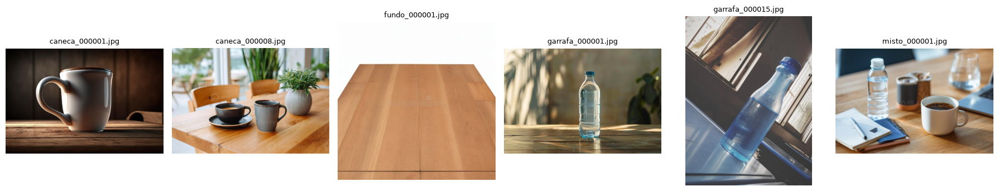

In [11]:
import hashlib

fotos_dir = "data/meu_detector/fotos"
my_images_dir = "data/meu_detector/images"
os.makedirs(my_images_dir, exist_ok=True)

seen_hashes = set()
prepared_paths = []

for root, _, files in sorted(os.walk(fotos_dir)):
    rel = os.path.relpath(root, fotos_dir)
    prefix = "" if rel == "." else rel.replace(os.sep, "_") + "_"
    for fname in sorted(files):
        fpath = os.path.join(root, fname)
        try:
            with Image.open(fpath) as im:
                im = ImageOps.exif_transpose(im).convert("RGB")
                if min(im.size) < 128:
                    continue
                im.thumbnail((1024, 1024))
                out_name = f"{prefix}{os.path.splitext(fname)[0]}.jpg"
                out_path = os.path.join(my_images_dir, out_name)
                im.save(out_path, "JPEG", quality=92)
            with open(out_path, "rb") as f:
                file_hash = hashlib.md5(f.read()).hexdigest()
            if file_hash in seen_hashes:
                os.remove(out_path)
            else:
                seen_hashes.add(file_hash)
                prepared_paths.append(out_path)
        except Exception as err:
            print(f"Ignorado {fpath}: {err}")

print(f"Total de imagens preparadas em {my_images_dir}: {len(prepared_paths)}")

sample_show = [
    p for p in prepared_paths
    if any(os.path.basename(p).startswith(k) for k in ("caneca_000001", "caneca_000008", "garrafa_000001", "garrafa_000015", "misto_000001", "fundo_000001"))
][:6]

fig, axes = plt.subplots(1, len(sample_show), figsize=(18, 3.5))
for ax, p in zip(axes, sample_show):
    ax.imshow(Image.open(p))
    ax.set_title(os.path.basename(p), fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### Exercício: rotulando

Rotular é desenhar à mão uma caixa em volta de cada objeto, em cada imagem, e escolher a classe. Todas as ferramentas abaixo exportam no formato YOLO. Exceto o Roboflow, todas são de código aberto:

| ferramenta | como usar | observação |
|---|---|---|
| [Roboflow](https://roboflow.com) | no site, com conta | a mais usada em tutoriais de YOLO, com rotulação assistida e projetos compartilhados. Não é de código aberto e, no plano gratuito, **os projetos ficam públicos**: qualquer pessoa pode ver e baixar as suas fotos. Não use fotos de pessoas ou da sua casa que você não queira publicar |
| [makesense.ai](https://www.makesense.ai) | no navegador, sem instalar nem criar conta | a mais simples; as imagens não saem do computador. Não salva o projeto: rotule tudo em uma sessão ou exporte no meio do caminho |
| [Label Studio](https://labelstud.io) | `pip install label-studio` e `label-studio start` | roda localmente no navegador e salva o projeto |
| [X-AnyLabeling](https://github.com/CVHub520/X-AnyLabeling) | programa de computador | sugere caixas automaticamente com modelos como o SAM e o próprio YOLO; você só corrige |
| [CVAT](https://www.cvat.ai) | instalado com Docker ou no site | a mais completa, feita para equipes rotulando juntas |

Qualquer que seja a ferramenta:

1. crie as classes e anote a ordem delas: no formato YOLO, a classe é um índice, e a sua lista de classes no notebook precisa estar na mesma ordem. A exportação traz um arquivo com os nomes na ordem certa (`classes.txt` ou `data.yaml`); confira por ele, porque algumas ferramentas, como o Roboflow, ordenam as classes em ordem alfabética;
2. desenhe caixas justas em volta dos objetos. Rotule **todos** os objetos das classes escolhidas: um objeto sem caixa ensina o modelo que aquilo é fundo;
3. exporte no formato YOLO e extraia o `.zip` em uma pasta, por exemplo `data/meu_detector/export`.

No makesense: *Get Started*, arraste as imagens de `data/meu_detector/images`, escolha *Object Detection*, crie as classes, rotule e exporte em *Actions → Export Annotations → YOLO*.

No Roboflow, ao gerar a versão do dataset, remova o pré-processamento *Resize* e não aplique aumento de dados: o YOLO já faz aumento de dados no treino, e cópias aumentadas de uma mesma foto acabariam em treino e validação ao mesmo tempo. Exporte no formato YOLO mais recente da lista (*YOLO26* ou *YOLOv11*): o formato dos arquivos é o mesmo.

Cada ferramenta organiza a exportação de um jeito: o makesense entrega só os `.txt`; o Label Studio, pastas `images` e `labels`; o Roboflow, pastas `train`, `valid` e `test`. Junte tudo em duas pastas, uma de imagens e uma de anotações, em que cada imagem `foto.jpg` tenha a anotação `foto.txt`. Cuidado: algumas ferramentas renomeiam os arquivos na exportação; nesse caso, use as imagens que vieram na exportação, e não as originais.

In [12]:
my_labels_dir = "data/meu_detector/labels"
classes = ["caneca", "garrafa"]

print("Classes:", classes)
print("Imagens:", len(os.listdir(my_images_dir)), "| Arquivos de anotação:", len(os.listdir(my_labels_dir)))

Classes: ['caneca', 'garrafa']
Imagens: 100 | Arquivos de anotação: 94


### Exercício: conferindo as anotações

Antes de treinar, confira as anotações. Erros aqui não dão mensagem de erro no treino: o modelo simplesmente aprende errado.

- todo `.txt` corresponde a uma imagem com o mesmo nome?
- cada linha tem 5 valores, e o índice da classe existe na sua lista?
- quantas imagens foram rotuladas, e quantas caixas há de cada classe? Classes com bem menos caixas que as outras vão ser mais difíceis, como vimos no exemplo;
- desenhe algumas imagens com `show_labels`: as caixas estão no lugar e com o nome certo?

Imagens rotuladas: 94 | Imagens de fundo (sem objetos): 6
  caneca    :  69 caixas
  garrafa   :  50 caixas


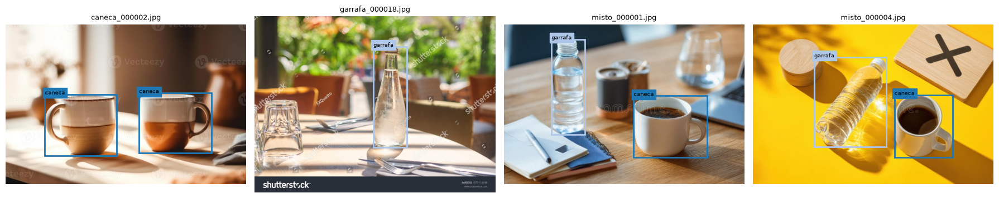

In [13]:
image_stems = {os.path.splitext(f)[0]: f for f in os.listdir(my_images_dir)}
label_stems = {os.path.splitext(f)[0]: f for f in os.listdir(my_labels_dir) if f.endswith(".txt")}

orphan_labels = set(label_stems) - set(image_stems)
assert not orphan_labels, f"Anotações sem imagem correspondente: {orphan_labels}"

class_counts = [0] * len(classes)
labeled_images = 0
background_images = 0

for stem, img_name in sorted(image_stems.items()):
    if stem not in label_stems:
        background_images += 1
        continue
    lines = [l.strip() for l in open(os.path.join(my_labels_dir, label_stems[stem])).read().splitlines() if l.strip()]
    if not lines:
        background_images += 1
        continue
    labeled_images += 1
    for line in lines:
        parts = line.split()
        assert len(parts) == 5, f"Linha inválida em {stem}.txt: {line}"
        cid = int(parts[0])
        assert 0 <= cid < len(classes), f"Índice de classe inválido {cid} em {stem}.txt"
        coords = [float(v) for v in parts[1:]]
        assert all(0.0 <= v <= 1.0 for v in coords), f"Coordenadas fora de [0, 1] em {stem}.txt: {line}"
        class_counts[cid] += 1

print(f"Imagens rotuladas: {labeled_images} | Imagens de fundo (sem objetos): {background_images}")
for name, count in zip(classes, class_counts):
    print(f"  {name:10s}: {count:3d} caixas")

preview_names = ["caneca_000002.jpg", "garrafa_000018.jpg", "misto_000001.jpg", "misto_000004.jpg"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, name in zip(axes, preview_names):
    lbl_name = os.path.splitext(name)[0] + ".txt"
    show_labels(ax, os.path.join(my_images_dir, name), os.path.join(my_labels_dir, lbl_name), classes)
    ax.set_title(name, fontsize=9)
plt.tight_layout()
plt.show()

### Exercício: treino

Organize o dataset na estrutura de pastas do YOLO, em `data/meu_detector/yolo`, sorteando cerca de 20% das imagens para a validação. Cada anotação precisa ir para o mesmo conjunto da sua imagem. Depois, escreva o `data.yaml` com `write_data_yaml`. Com poucas dezenas de imagens, não sobra o bastante para um conjunto de teste separado: no fim, testamos com imagens novas.

Em seguida, faça o ajuste fino de um YOLO26 pré-treinado para o seu dataset, salvando os resultados em `runs/meu_detector`. Use o mesmo `project=runs_dir` do exemplo, para os pesos irem para essa pasta. Algumas escolhas:

- o tamanho do modelo: o `yolo26n.pt` é o mais rápido; o `yolo26s.pt` costuma ser mais preciso e ainda treina rápido em uma GPU;
- `imgsz`: o padrão de 640 é um bom começo. Objetos pequenos na foto pedem um valor maior; se faltar memória, reduza o `batch`;
- `epochs`: com poucas imagens, cada época é rápida; algo entre 30 e 100 épocas é comum;
- `freeze`: o número de camadas iniciais congeladas. Com `freeze=10`, só a parte final da rede é treinada, o que ajuda com poucas imagens.

Os resultados de cada época ficam em `runs/meu_detector/results.csv`, e as curvas, em `runs/meu_detector/results.png`.

In [14]:
my_yolo_dir = "data/meu_detector/yolo"
if os.path.exists(my_yolo_dir):
    shutil.rmtree(my_yolo_dir)

for split in ["train", "val"]:
    os.makedirs(os.path.join(my_yolo_dir, "images", split), exist_ok=True)
    os.makedirs(os.path.join(my_yolo_dir, "labels", split), exist_ok=True)

all_names = sorted(os.listdir(my_images_dir))
rng = random.Random(42)
rng.shuffle(all_names)

n_val = int(0.20 * len(all_names))
splits = {"val": all_names[:n_val], "train": all_names[n_val:]}

for split, names in splits.items():
    for name in names:
        shutil.copy(os.path.join(my_images_dir, name), os.path.join(my_yolo_dir, "images", split, name))
        lbl_name = os.path.splitext(name)[0] + ".txt"
        src_lbl = os.path.join(my_labels_dir, lbl_name)
        if os.path.exists(src_lbl):
            shutil.copy(src_lbl, os.path.join(my_yolo_dir, "labels", split, lbl_name))
    print(f"{split:5s}: {len(names)} imagens")

my_yaml = write_data_yaml(my_yolo_dir, classes)
print("\n" + open(my_yaml).read())

runs_dir = os.path.abspath("runs")
my_model = YOLO("yolo26s.pt")
my_model.train(
    data=my_yaml,
    epochs=60,
    imgsz=640,
    batch=16,
    freeze=10,
    project=runs_dir,
    name="meu_detector",
    exist_ok=True,
)

val  : 20 imagens
train: 80 imagens

path: /home/alomyr/Projetos/UFRN-06/APRENDIZADO-PROFUNDO/tarefa2° /data/meu_detector/yolo
train: images/train
val: images/val
names:
  0: caneca
  1: garrafa



New https://pypi.org/project/ultralytics/8.4.217 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.216 🚀 Python-3.14.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3070, 7839MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/meu_detector/yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=meu_detector, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


... (512 outputs left out)

               garrafa          9          9      0.988          1      0.995      0.863


Speed: 0.2ms preprocess, 6.6ms inference, 0.0ms loss, 0.3ms postprocess per image


Results saved to /home/alomyr/Projetos/UFRN-06/APRENDIZADO-PROFUNDO/tarefa2° /runs/meu_detector


ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x776210197150>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

Nas curvas, as perdas de treino e de validação aparecem separadas em três partes, como no detector que fizemos do zero: `box_loss` (a sobreposição entre a caixa prevista e a verdadeira, medida pelo IoU), `cls_loss` (a classe) e `l1_loss` (a distância entre as bordas das duas caixas). Nas versões anteriores, como o YOLO11, a terceira perda é a `dfl_loss`, que prevê cada borda como uma distribuição sobre posições possíveis; o YOLO26 trocou essa distribuição por uma regressão direta. Se as perdas de validação sobem enquanto as de treino descem, o modelo está sobreajustando: menos épocas, mais imagens ou `freeze` maior ajudam.

### Exercício: avaliação

Avalie o seu modelo:

- mostre as curvas de treino, em `runs/meu_detector/results.png`;
- carregue os pesos da melhor época e calcule o mAP50, o mAP50-95 e a AP de cada classe no conjunto de validação;
- mostre as detecções em algumas imagens de validação e compare com as caixas que você desenhou.

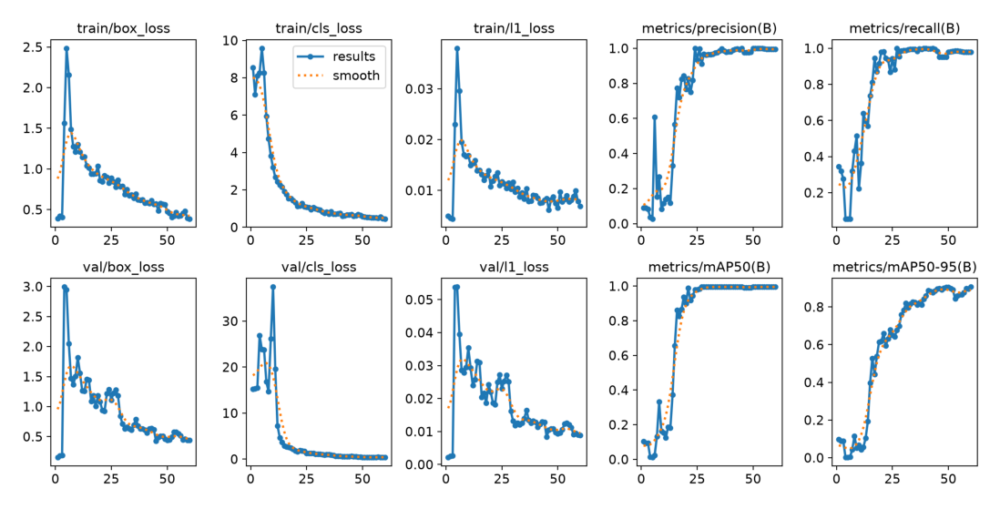

Ultralytics 8.4.216 🚀 Python-3.14.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA GeForce RTX 3070, 7839MiB)


YOLO26s summary (fused): 120 layers, 9,465,954 parameters, 0 gradients, 20.8 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4253.4±2094.9 MB/s, size: 77.7 KB)


val: Scanning /home/alomyr/Projetos/UFRN-06/APRENDIZADO-PROFUNDO/tarefa2° /data/meu_detector/yolo/labels/val.cache... 18 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 5.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 50% ━━━━━━────── 1/2 3.6s/it 1.1s<3.6s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.8it/s 1.1s

                   all         20         21      0.994      0.977      0.995      0.904


Speed: 0.7ms preprocess, 4.2ms inference, 0.0ms loss, 0.9ms postprocess per image


Results saved to /home/alomyr/Projetos/UFRN-06/APRENDIZADO-PROFUNDO/tarefa2° /runs/meu_detector_val


validação: mAP50 0.995, mAP50-95 0.904

AP50 por classe na validação:
  garrafa   : 0.995
  caneca    : 0.995


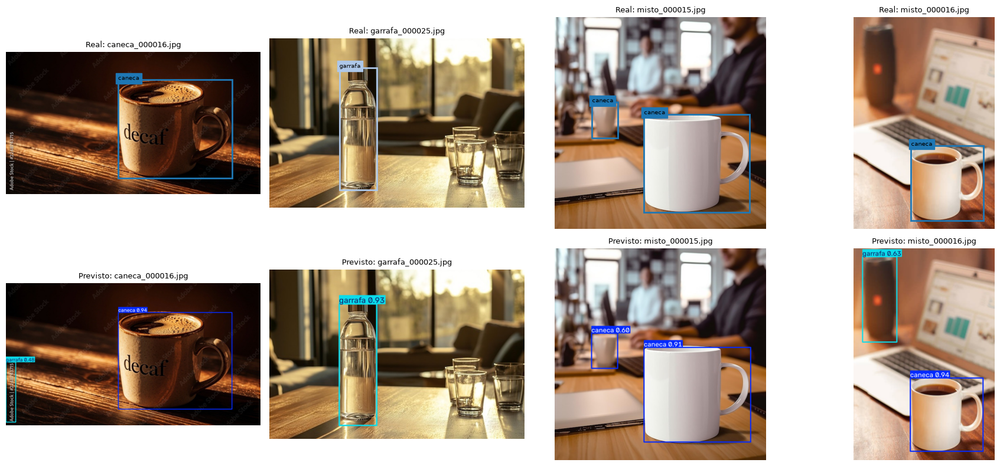

In [15]:
results_img = Image.open(os.path.join(runs_dir, "meu_detector", "results.png"))
plt.figure(figsize=(14, 7))
plt.imshow(results_img)
plt.axis("off")
plt.show()

best_my_model = YOLO(os.path.join(runs_dir, "meu_detector", "weights", "best.pt"))
my_val_metrics = best_my_model.val(data=my_yaml, split="val", project=runs_dir, name="meu_detector_val", exist_ok=True, verbose=False)
print(f"validação: mAP50 {my_val_metrics.box.map50:.3f}, mAP50-95 {my_val_metrics.box.map:.3f}")
print("\nAP50 por classe na validação:")
for ap50, index in sorted(zip(my_val_metrics.box.ap50, my_val_metrics.box.ap_class_index), reverse=True):
    print(f"  {classes[index]:10s}: {ap50:.3f}")

val_img_dir = os.path.join(my_yolo_dir, "images", "val")
val_lbl_dir = os.path.join(my_yolo_dir, "labels", "val")
val_samples = ["caneca_000016.jpg", "garrafa_000025.jpg", "misto_000015.jpg", "misto_000016.jpg"]
val_preds = best_my_model.predict([os.path.join(val_img_dir, n) for n in val_samples], conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for col, (name, res) in enumerate(zip(val_samples, val_preds)):
    show_labels(axes[0, col], os.path.join(val_img_dir, name), os.path.join(val_lbl_dir, os.path.splitext(name)[0] + ".txt"), classes)
    axes[0, col].set_title(f"Real: {name}", fontsize=9)
    axes[1, col].imshow(res.plot()[:, :, ::-1])
    axes[1, col].set_title(f"Previsto: {name}", fontsize=9)
    axes[1, col].axis("off")
plt.tight_layout()
plt.show()

As curvas em `results.png` mostram queda consistente das perdas de treino e validação (`box_loss`, `cls_loss` e `l1_loss`) ao longo das 60 épocas, sem sinais de sobreajuste, atingindo **mAP50 = 0.995** e **mAP50-95 = 0.904** no conjunto de validação (`AP50 = 0.995` tanto para `caneca` quanto para `garrafa`).

Comparando as previsões com as anotações reais na validação:
- **Acertos consistentes**: o modelo localiza bem múltiplas instâncias e objetos desfocados ao fundo (`misto_000015.jpg`, com `0.91` na caneca principal e `0.60` na secundária) e aprendeu a não confundir copos de vidro transparentes com canecas nem com garrafas (`garrafa_000025.jpg`).
- **Falsos positivos por geometria parecida**: objetos cilíndricos escuros e verticais fora das classes — como a caixa de som atrás do notebook em `misto_000016.jpg` (`garrafa 0.63`) — ou faixas verticais finas de texto/marca d'água (`Adobe Stock` na borda esquerda de `caneca_000016.jpg`, `garrafa 0.48`) ainda podem gerar detecções falsas da classe `garrafa`, pois compartilham proporção alongada vertical com garrafas térmicas/escuras do treino.

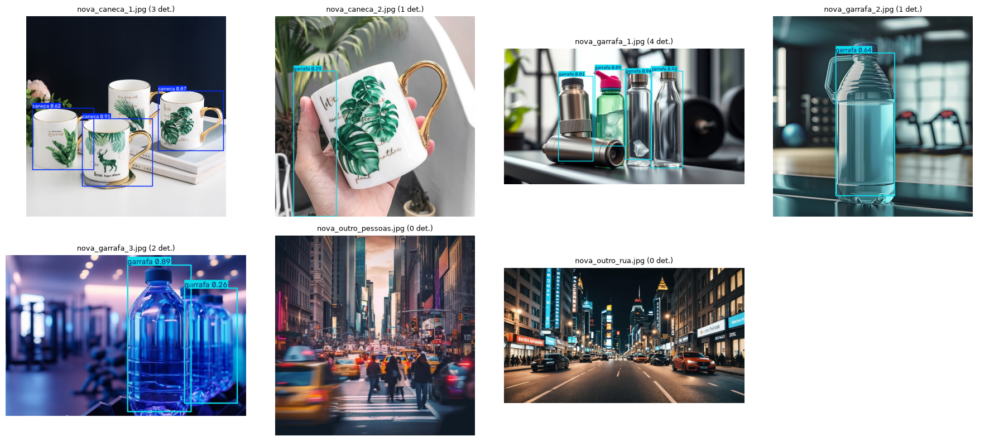

nova_caneca_1.jpg         -> ['caneca (0.91)', 'caneca (0.87)', 'caneca (0.62)']
nova_caneca_2.jpg         -> ['garrafa (0.29)']
nova_garrafa_1.jpg        -> ['garrafa (0.94)', 'garrafa (0.92)', 'garrafa (0.89)', 'garrafa (0.81)']
nova_garrafa_2.jpg        -> ['garrafa (0.64)']
nova_garrafa_3.jpg        -> ['garrafa (0.89)', 'garrafa (0.26)']
nova_outro_pessoas.jpg    -> ['nenhuma detecção']
nova_outro_rua.jpg        -> ['nenhuma detecção']


In [16]:
novas_dir = "data/meu_detector/novas"
novas_paths = [os.path.join(novas_dir, n) for n in sorted(os.listdir(novas_dir)) if n.endswith(".jpg")]
novas_results = best_my_model.predict(novas_paths, conf=0.25, verbose=False)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, p, res in zip(axes.flat, novas_paths, novas_results):
    ax.imshow(res.plot()[:, :, ::-1])
    n_det = len(res.boxes)
    ax.set_title(f"{os.path.basename(p)} ({n_det} det.)", fontsize=9)
    ax.axis("off")
for ax in axes.flat[len(novas_paths):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

for p, res in zip(novas_paths, novas_results):
    dets = [f"{classes[int(b.cls)]} ({b.conf.item():.2f})" for b in res.boxes]
    print(f"{os.path.basename(p):25s} -> {dets if dets else ['nenhuma detecção']}")

Nas imagens novas (`data/meu_detector/novas/`), vindas de outras buscas e contextos, o comportamento mostra tanto a capacidade de generalização quanto os limites do conjunto de treino:

- **Desempenho em objetos conhecidos e sobrepostos**:
  - Em `nova_caneca_1.jpg` (três canecas sobrepostas), o modelo detecta corretamente 3 canecas (`0.91`, `0.87`, `0.62`), embora com leve desalinhamento/omissão na caneca mais ocluída ao fundo.
  - Em `nova_garrafa_1.jpg`, `nova_garrafa_2.jpg` e `nova_garrafa_3.jpg`, as garrafas em pé (de vidro, aço, plástico e galão com alça) são detectadas com boa confiança (`0.64` a `0.94`).
- **Queda fora da pose/contexto dominante**:
  - Em `nova_garrafa_1.jpg`, a garrafa metálica deitada em primeiro plano não foi detectada, refletindo o forte desbalanceamento de orientação no treino (quase todas as garrafas estavam em pé).
  - Em `nova_caneca_2.jpg`, uma caneca inclinada e parcialmente coberta por uma mão segurando-a não foi reconhecida como `caneca`, além de gerar um falso positivo de baixa confiança (`garrafa 0.29`) na borda esquerda (dedos/caule). O treino continha apenas canecas apoiadas sobre mesas.
- **Imagens sem nenhuma das classes (`nova_outro_pessoas.jpg` e `nova_outro_rua.jpg`)**:
  - O detector não gerou nenhuma caixa (`0` detecções), confirmando que o ajuste fino substituiu as 80 classes originais do COCO pelas 2 classes do problema (`caneca` e `garrafa`) e esqueceu pessoas e carros.